<a href="https://colab.research.google.com/github/machindie/Analisis-Cluster-Jaringan-Internet-Gratis/blob/main/KMeans.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Import Data**

In [ ]:
# 1. Import Library
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans
from scipy.stats import zscore
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

# **Load Data**

In [ ]:
# 2. Load Data
data = pd.read_excel("DATAKELJAR.xlsx")
data

,DESA,JUMLAH JARINGAN INTERNET,JUMLAH PENDUDUK,LUAS WILAYAH,KEPADATAN
0,LEKOBALO,1,3933,2.09,1881.818182
1,BULIIDE,1,3149,2.95,1067.457627
2,BULADU,3,4650,0.92,5054.347826
3,BIAWU,2,3638,0.28,12992.857143
4,LIMBA U I,2,3905,0.52,7509.615385
5,DULOMO SELATAN,3,5199,2.24,2320.982143
6,DEMBE JAYA,1,3484,0.96,3629.166667
7,HUANGOBOTU,3,8869,1.22,7269.672131
8,LIBUO,1,5679,1.33,4269.924812
9,HELEDULAA UTARA,1,5164,0.97,5323.711340


# **Preprocessing Data**

In [ ]:
#1 MISSING VALUE

# Cek total missing value per kolom
print("Jumlah missing value per kolom:")
print(data.isnull().sum())

# (Opsional) Cek proporsi missing value
print("\nProporsi missing value per kolom:")
print(data.isnull().mean())

Jumlah missing value per kolom:
DESA                        0
JUMLAH JARINGAN INTERNET    0
JUMLAH PENDUDUK             0
LUAS WILAYAH                0
KEPADATAN                   0
dtype: int64

Proporsi missing value per kolom:
DESA                        0.0
JUMLAH JARINGAN INTERNET    0.0
JUMLAH PENDUDUK             0.0
LUAS WILAYAH                0.0
KEPADATAN                   0.0
dtype: float64


Kolom-kolom yang memiliki outlier dan barisnya:

Kolom: JUMLAH JARINGAN INTERNET
Indeks outlier: [28, 37]

Kolom: JUMLAH PENDUDUK
Indeks outlier: [7]

Kolom: LUAS WILAYAH
Indeks outlier: [1, 18, 43, 48]

Kolom: KEPADATAN
Indeks outlier: [3, 46]


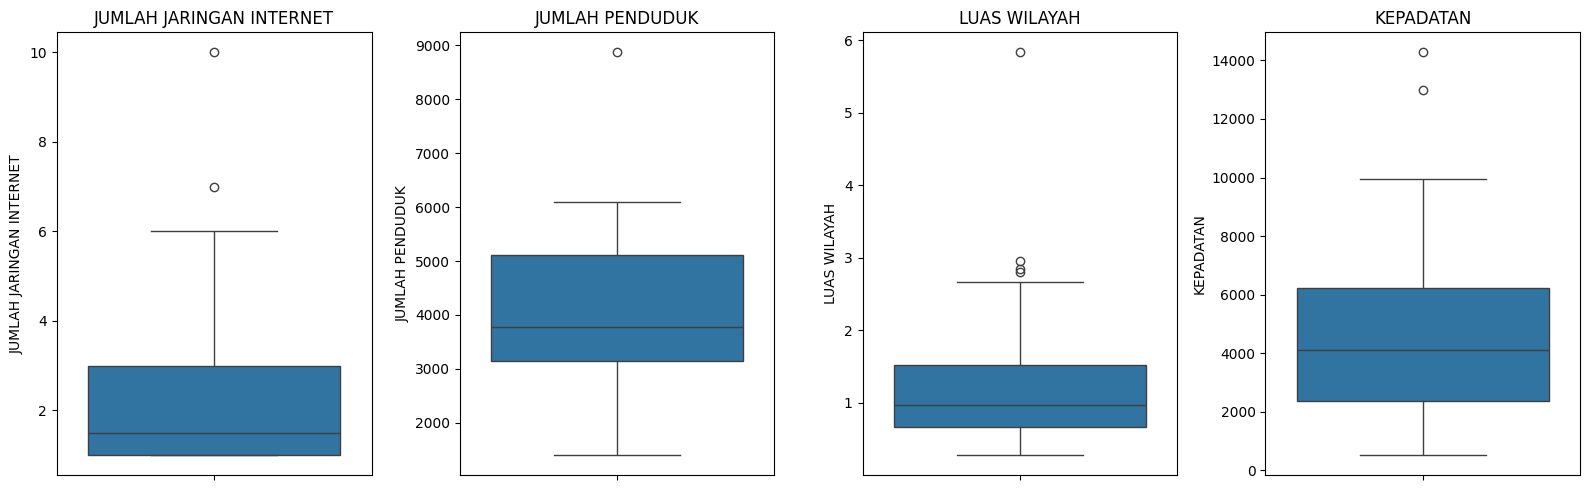

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Kolom numerik yang ingin dicek
kolom_numerik = ['JUMLAH JARINGAN INTERNET', 'JUMLAH PENDUDUK', 'LUAS WILAYAH', 'KEPADATAN']

# Fungsi untuk mendeteksi outlier
def cari_outlier(series):
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    return series[(series < lower_bound) | (series > upper_bound)].index

# Dictionary hasil outlier
outlier_dict = {}

# Cari outlier
for kolom in kolom_numerik:
    indeks_outlier = cari_outlier(data[kolom])
    if not indeks_outlier.empty:
        outlier_dict[kolom] = indeks_outlier.tolist()

# Visualisasi semua boxplot dalam satu frame horizontal
if outlier_dict:
    print("Kolom-kolom yang memiliki outlier dan barisnya:")
    for kolom, indeks in outlier_dict.items():
        print(f"\nKolom: {kolom}")
        print(f"Indeks outlier: {indeks}")

    plt.figure(figsize=(4 * len(outlier_dict), 5))  # Panjang disesuaikan
    for i, kolom in enumerate(outlier_dict):
        plt.subplot(1, len(outlier_dict), i + 1)
        sns.boxplot(y=data[kolom])
        plt.title(kolom)
    plt.tight_layout()
    plt.show()
else:
    print("Tidak ada outlier yang terdeteksi di kolom-kolom numerik.")

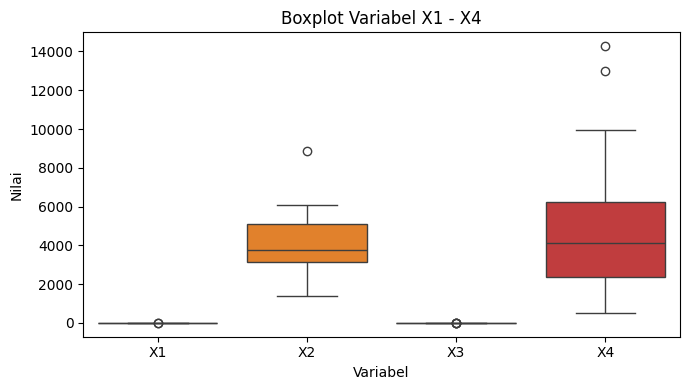

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Ambil hanya kolom yang mengandung outlier
kolom_outlier = list(outlier_dict.keys())

# Buat mapping nama asli ke label X1, X2, X3, X4
label_baru = {kolom: f'X{i+1}' for i, kolom in enumerate(kolom_outlier)}

# Subset data hanya kolom yang punya outlier
data_outlier = data[kolom_outlier].copy()

# Ganti nama kolom jadi X1, X2, dst.
data_outlier.rename(columns=label_baru, inplace=True)

# Buat boxplot dalam satu frame
plt.figure(figsize=(7, 4))
sns.boxplot(data=data_outlier)
plt.title("Boxplot Variabel X1 - X4")
plt.ylabel("Nilai")
plt.xlabel("Variabel")
plt.tight_layout()
plt.show()

Kolom-kolom yang memiliki outlier dan barisnya:

Kolom: JUMLAH JARINGAN INTERNET
Indeks outlier: [28, 37]

Kolom: JUMLAH PENDUDUK
Indeks outlier: [7]

Kolom: LUAS WILAYAH
Indeks outlier: [1, 18, 43, 48]

Kolom: KEPADATAN
Indeks outlier: [3, 46]


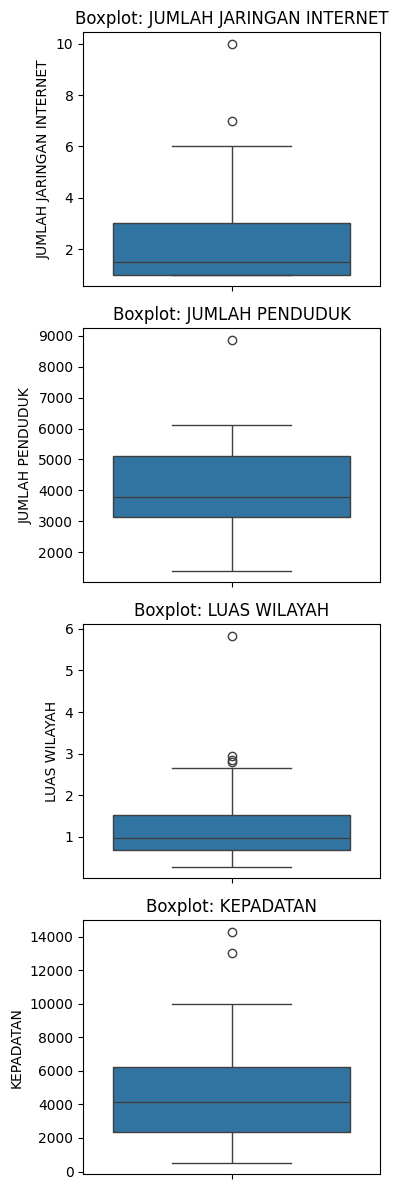

In [ ]:
#2 OUTLIER

# Kolom numerik yang ingin dicek
kolom_numerik = ['JUMLAH JARINGAN INTERNET', 'JUMLAH PENDUDUK', 'LUAS WILAYAH', 'KEPADATAN']

# Fungsi untuk mendeteksi outlier dan mengembalikan indeks baris yang merupakan outlier
def cari_outlier(series):
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    return series[(series < lower_bound) | (series > upper_bound)].index

# Dictionary untuk menyimpan hasil outlier per kolom
outlier_dict = {}

for kolom in kolom_numerik:
    indeks_outlier = cari_outlier(data[kolom])
    if not indeks_outlier.empty:
        outlier_dict[kolom] = indeks_outlier.tolist()

# Tampilkan hasil outlier
if outlier_dict:
    print("Kolom-kolom yang memiliki outlier dan barisnya:")
    for kolom, indeks in outlier_dict.items():
        print(f"\nKolom: {kolom}")
        print(f"Indeks outlier: {indeks}")

    # Tampilkan boxplot hanya untuk kolom yang punya outlier
    plt.figure(figsize=(4, 3 * len(outlier_dict)))
    for i, kolom in enumerate(outlier_dict):
        plt.subplot(len(outlier_dict), 1, i+1)
        sns.boxplot(y=data[kolom])
        plt.title(f'Boxplot: {kolom}')
        plt.tight_layout()
    plt.show()
else:
    print("Tidak ada outlier yang terdeteksi di kolom-kolom numerik.")

In [ ]:
#4 Uji Multikolinearitas (VIF)

fitur_awal = ['JUMLAH JARINGAN INTERNET', 'JUMLAH PENDUDUK', 'LUAS WILAYAH', 'KEPADATAN']
X_vif = add_constant(data[fitur_awal])
vif_df = pd.DataFrame()
vif_df["variabel"] = X_vif.columns
vif_df["VIF"] = [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
print(vif_df)

                   variabel        VIF
0                     const  17.446433
1  JUMLAH JARINGAN INTERNET   1.173273
2           JUMLAH PENDUDUK   1.420464
3              LUAS WILAYAH   1.964379
4                 KEPADATAN   2.268983


In [ ]:
#5 standarisasi data menggunakan RobustScaler

# Kolom numerik yang ingin diskalakan
kolom_numerik = ['JUMLAH JARINGAN INTERNET', 'JUMLAH PENDUDUK', 'LUAS WILAYAH', 'KEPADATAN']

# Inisialisasi scaler
scaler = RobustScaler()

# Transformasi kolom numerik
scaled_data = scaler.fit_transform(data[kolom_numerik])
scaled_data

array([[-2.50000000e-01,  8.18937940e-02,  1.33531157e+00,
        -5.77367502e-01],
       [-2.50000000e-01, -3.19385797e-01,  2.35608309e+00,
        -7.87539610e-01],
       [ 7.50000000e-01,  4.48880358e-01, -5.34124629e-02,
         2.41406494e-01],
       [ 2.50000000e-01, -6.90978887e-02, -8.13056380e-01,
         2.29019586e+00],
       [ 2.50000000e-01,  6.75623800e-02, -5.28189911e-01,
         8.75067784e-01],
       [ 7.50000000e-01,  7.29878439e-01,  1.51335312e+00,
        -4.64027022e-01],
       [-2.50000000e-01, -1.47920665e-01, -5.93471810e-03,
        -1.26407649e-01],
       [ 7.50000000e-01,  2.60831734e+00,  3.02670623e-01,
         8.13142659e-01],
       [-2.50000000e-01,  9.75559821e-01,  4.33234421e-01,
         3.89607368e-02],
       [-2.50000000e-01,  7.11964171e-01,  5.93471810e-03,
         3.10924470e-01],
       [ 7.50000000e-01, -4.95457454e-01, -6.11275964e-01,
         5.45681877e-01],
       [ 7.50000000e-01,  3.30134357e-01,  6.70623145e-01,
      

# **KMeans**

k=1, SSE=163.19, Selisih= -
k=2, SSE=109.19, Selisih=54.00
k=3, SSE=79.20, Selisih=29.99
k=4, SSE=62.84, Selisih=16.35
k=5, SSE=50.59, Selisih=12.25
k=6, SSE=42.69, Selisih=7.90
k=7, SSE=34.05, Selisih=8.64
k=8, SSE=29.04, Selisih=5.01
k=9, SSE=24.36, Selisih=4.69
k=10, SSE=21.41, Selisih=2.94


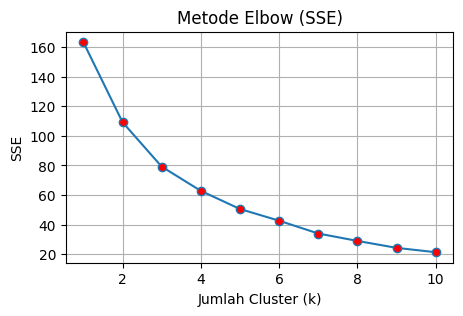

In [ ]:

sse = []  # Simpan SSE
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(scaled_data)
    sse.append(kmeans.inertia_)

# Hitung selisih SSE antar k
sse_diff = [sse[i] - sse[i+1] for i in range(len(sse)-1)]

# Tampilkan SSE dan selisihnya
for i in range(len(sse)):
    if i == 0:
        print(f"k={i+1}, SSE={sse[i]:.2f}, Selisih= -")
    else:
        print(f"k={i+1}, SSE={sse[i]:.2f}, Selisih={sse_diff[i-1]:.2f}")

# Plot SSE
plt.figure(figsize=(5,3))
plt.plot(range(1, 11), sse, marker='o', markerfacecolor='red')
plt.title('Metode Elbow (SSE)')
plt.xlabel('Jumlah Cluster (k)')
plt.ylabel('SSE')
plt.grid(True)
plt.show()

Jumlah Cluster: 2, Silhouette Score: 0.3275
Jumlah Cluster: 3, Silhouette Score: 0.2095
Jumlah Cluster: 4, Silhouette Score: 0.2403
Jumlah Cluster: 5, Silhouette Score: 0.2483
Jumlah Cluster: 6, Silhouette Score: 0.2571
Jumlah Cluster: 7, Silhouette Score: 0.2328
Jumlah Cluster: 8, Silhouette Score: 0.2849
Jumlah Cluster: 9, Silhouette Score: 0.3090
Jumlah Cluster: 10, Silhouette Score: 0.2828


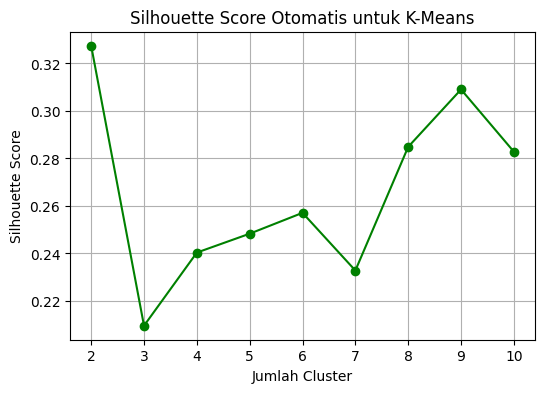

In [ ]:
#1 Menentukan jumlah cluster untuk k means
# Misalnya data_scaled adalah data yang telah distandarisasi dengan RobustScaler
range_k = range(2, 11)
hasil_silhouette = []

for k in range_k:
    model = KMeans(n_clusters=k, random_state=42)
    labels = model.fit_predict(scaled_data)

    score = silhouette_score(scaled_data, labels)
    hasil_silhouette.append((k, score))
    print(f"Jumlah Cluster: {k}, Silhouette Score: {score:.4f}")

# Simpan hasil ke DataFrame dan visualisasikan
df_silhouette_auto = pd.DataFrame(hasil_silhouette, columns=["Jumlah Cluster", "Silhouette Score"])

# Plot
plt.figure(figsize=(6, 4))
plt.plot(df_silhouette_auto["Jumlah Cluster"], df_silhouette_auto["Silhouette Score"], marker='o', color='green')
plt.title("Silhouette Score Otomatis untuk K-Means")
plt.xlabel("Jumlah Cluster")
plt.ylabel("Silhouette Score")
plt.grid(True)
plt.show()

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import davies_bouldin_score

dbi_scores_kmeans = []
cluster_range = range(2, 11)

for k in cluster_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(scaled_data)  # data_scaled adalah data yang sudah di-scaling
    dbi = davies_bouldin_score(scaled_data, labels)
    dbi_scores_kmeans.append(dbi)
    print(f"K-Means: Cluster {k}, DBI = {dbi:.4f}")

K-Means: Cluster 2, DBI = 1.0344
K-Means: Cluster 3, DBI = 1.5602
K-Means: Cluster 4, DBI = 1.0840
K-Means: Cluster 5, DBI = 0.9227
K-Means: Cluster 6, DBI = 0.9752
K-Means: Cluster 7, DBI = 0.9616
K-Means: Cluster 8, DBI = 0.8927
K-Means: Cluster 9, DBI = 0.8038
K-Means: Cluster 10, DBI = 0.8202


In [ ]:
# 2 Menginisiasi centroid
k = 2

kmeans = KMeans(n_clusters=k, init='random', n_init=1, max_iter=1, random_state=42)
kmeans.fit(scaled_data)

centroids = kmeans.cluster_centers_
print("Centroid Awal:")
print(centroids)

Centroid Awal:
[[ 0.21428571  0.27949913  1.78635015 -0.50090591]
 [ 0.47222222  0.11466553 -0.14210353  0.36599192]]


In [ ]:
#3 Perhitungan Euclidean Distance secara manual (tanpa cdist)
def euclidean_distance(a, b):
    return np.sqrt(np.sum((a - b) ** 2))

# Hitung jarak manual: baris = data, kolom = centroid
distances = np.zeros((scaled_data.shape[0], k))

for i in range(scaled_data.shape[0]):
    for j in range(k):
        distances[i, j] = euclidean_distance(scaled_data[i], centroids[j])

print("Contoh jarak (baris: data, kolom: centroid):")
print(distances[:50])

Contoh jarak (baris: data, kolom: centroid):
[[0.68109564 1.8961438 ]
 [0.99044378 2.8777729 ]
 [2.06190057 0.46070346]
 [3.83013822 2.05812785]
 [2.70122046 0.67810202]
 [0.75214277 1.97106965]
 [1.93669381 0.92279777]
 [3.1045793  2.5871273 ]
 [1.68001187 1.3041116 ]
 [2.05706949 0.95043061]
 [2.7805583  0.83774806]
 [1.25216976 1.11878512]
 [2.3312511  0.32760699]
 [3.02829695 1.11974875]
 [2.01749289 0.34267788]
 [2.31239763 0.84777073]
 [2.02590175 0.62620594]
 [1.61331352 0.88015809]
 [1.02386149 2.80557312]
 [1.34177257 1.26421197]
 [2.40196637 2.34453692]
 [0.91219696 1.59837335]
 [1.69855663 1.58411656]
 [0.795402   2.54125184]
 [1.49721449 0.95063498]
 [3.39659062 1.77769436]
 [3.51023596 2.2111087 ]
 [2.82152455 1.38630371]
 [4.50893267 3.81192414]
 [2.40395486 1.14780495]
 [1.29731767 1.24322618]
 [2.41081003 1.63607822]
 [0.88714519 1.85727761]
 [2.62410402 0.90492361]
 [2.17230192 0.76067968]
 [3.13270047 1.5134923 ]
 [2.71053271 1.05321243]
 [3.42053513 2.42470562]
 [2.1

In [ ]:
# 4 Mengelompokkan semua data pengamatan berlandaskan kedekatannya dengan centroid atau jarak minimum

clusters = np.argmin(distances, axis=1)
print("Cluster untuk 50 data:", clusters[:50])

Cluster untuk 50 data: [0 0 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 0 1 1 0 1 0 1 1 1 1 1 1 1 1 0 1 1 1 1
 1 1 1 1 1 1 0 0 1 1 1 0 0]


In [ ]:
# 5 Perbaharui nilai hasil centroid baru yang di peroleh dari rata‑rata (means) cluster yang sesuai

new_centroids = np.array([scaled_data[clusters == i].mean(axis=0) for i in range(k)])
print("Centroid Baru:")
print(new_centroids)

Centroid Baru:
[[-0.06818182 -0.01279591  2.10466685 -0.66757308]
 [ 0.53205128  0.20978723 -0.08354257  0.34631616]]


In [ ]:
# 6 Ulang langkah 3 sampai 5 sampai selesai
max_iter = 100
tolerance = 1e-4

for i in range(max_iter):
    old_centroids = centroids.copy()

    # Tahap 3: Hitung jarak secara manual
    distances = np.zeros((scaled_data.shape[0], k))
    for m in range(scaled_data.shape[0]):
        for n in range(k):
            distances[m, n] = euclidean_distance(scaled_data[m], centroids[n])

    clusters = np.argmin(distances, axis=1)

    # Tahap 5: Update centroid
    centroids = np.array([scaled_data[clusters == j].mean(axis=0) for j in range(k)])

    if np.all(np.abs(centroids - old_centroids) < tolerance):
        print(f"Konvergen pada iterasi ke-{i+1}")
        break

Konvergen pada iterasi ke-2


In [ ]:
#Menampilkan hasil cluster tiap data
for idx, label in enumerate(clusters):
    print(f"Data ke-{idx} masuk ke cluster {label}")

Data ke-0 masuk ke cluster 0
Data ke-1 masuk ke cluster 0
Data ke-2 masuk ke cluster 1
Data ke-3 masuk ke cluster 1
Data ke-4 masuk ke cluster 1
Data ke-5 masuk ke cluster 0
Data ke-6 masuk ke cluster 1
Data ke-7 masuk ke cluster 1
Data ke-8 masuk ke cluster 1
Data ke-9 masuk ke cluster 1
Data ke-10 masuk ke cluster 1
Data ke-11 masuk ke cluster 1
Data ke-12 masuk ke cluster 1
Data ke-13 masuk ke cluster 1
Data ke-14 masuk ke cluster 1
Data ke-15 masuk ke cluster 1
Data ke-16 masuk ke cluster 1
Data ke-17 masuk ke cluster 1
Data ke-18 masuk ke cluster 0
Data ke-19 masuk ke cluster 1
Data ke-20 masuk ke cluster 1
Data ke-21 masuk ke cluster 0
Data ke-22 masuk ke cluster 1
Data ke-23 masuk ke cluster 0
Data ke-24 masuk ke cluster 1
Data ke-25 masuk ke cluster 1
Data ke-26 masuk ke cluster 1
Data ke-27 masuk ke cluster 1
Data ke-28 masuk ke cluster 1
Data ke-29 masuk ke cluster 1
Data ke-30 masuk ke cluster 1
Data ke-31 masuk ke cluster 1
Data ke-32 masuk ke cluster 0
Data ke-33 masuk ke 

In [ ]:
#Menampilkan Anggota tiap cluster
unique, counts = np.unique(clusters, return_counts=True)
for clust, count in zip(unique, counts):
    print(f"Cluster {clust}: {count} data")

Cluster 0: 11 data
Cluster 1: 39 data


In [ ]:
clusters

array([0, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0,
       1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0,
       0, 1, 1, 1, 0, 0])

In [ ]:
#Menampilkan centroid akhir
print("Centroid akhir tiap cluster:")
print(centroids)

Centroid akhir tiap cluster:
[[-0.06818182 -0.01279591  2.10466685 -0.66757308]
 [ 0.53205128  0.20978723 -0.08354257  0.34631616]]


# **Visualisasi Hasil K-Means Custering**

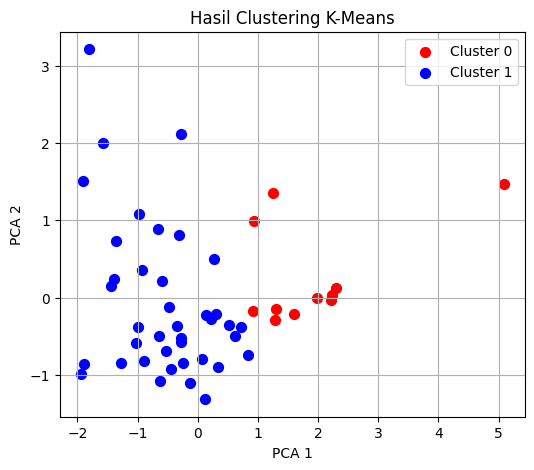

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(6, 5))

colors = ['red', 'blue']  # Warna untuk cluster 0 dan 1

for cluster_id in np.unique(clusters):
    idx = clusters == cluster_id
    plt.scatter(data_2d[idx, 0], data_2d[idx, 1],
                c=colors[cluster_id], label=f'Cluster {cluster_id}', s=50)

plt.title("Hasil Clustering K-Means")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.legend()
plt.grid(True)
plt.show()


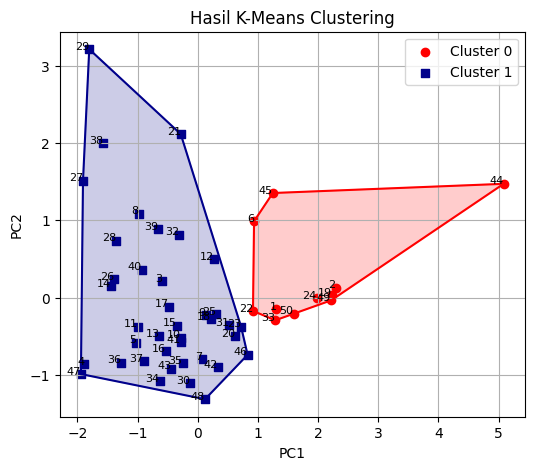

In [ ]:
import matplotlib.pyplot as plt
from scipy.spatial import ConvexHull
import numpy as np

# Contoh data dummy (ganti dengan datamu sendiri)
# pca_data = np.array([[...], ...])  # shape: (n_samples, 2)
# clusters = np.array([...])         # shape: (n_samples,)
# centroids = np.array([[...], [...]])  # shape: (2, 2)

from sklearn.decomposition import PCA

# Asumsikan data_scaled dan clusters sudah ada
pca = PCA(n_components=2)
data_2d = pca.fit_transform(dscaled_data)

# Jika punya centroid dari data_scaled:
centroids_2d = pca.transform(centroids)

# Visualisasi pakai data_2d dan centroids_2d

# Warna dan marker untuk 2 cluster
colors = ['red', 'darkblue']
markers = ['o', 's']

plt.figure(figsize=(6, 5))

for i in range(2):  # Hanya 2 cluster: 0 dan 1
    points = data_2d[clusters == i]
    indices = np.where(clusters == i)[0]

    # Titik-titik cluster
    plt.scatter(points[:, 0], points[:, 1], color=colors[i], marker=markers[i], label=f'Cluster {i}')

    # Label angka untuk masing-masing titik
    for j, (x, y) in zip(indices, points):
        plt.text(x, y, str(j+1), fontsize=8, ha='right')

    # Gambar area cluster dengan convex hull jika titiknya cukup
    if len(points) >= 3:
        hull = ConvexHull(points)
        plt.fill(points[hull.vertices, 0], points[hull.vertices, 1], color=colors[i], alpha=0.2)
        for simplex in hull.simplices:
            plt.plot(points[simplex, 0], points[simplex, 1], c=colors[i])

# Plot centroid
plt.scatter(centroids[:, 0], centroids[:, 1], s=0)

plt.title("Hasil K-Means Clustering")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend()
plt.grid(True)
plt.show()


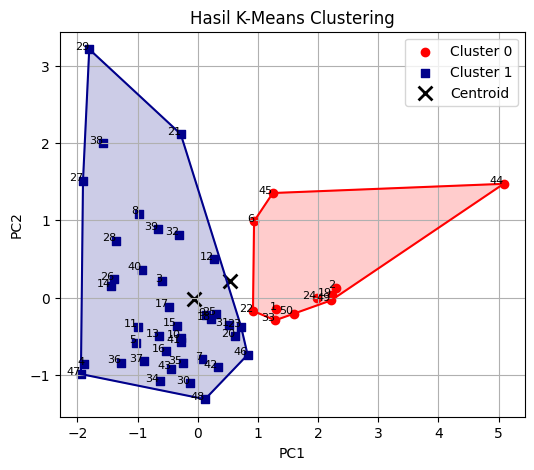

In [ ]:
import matplotlib.pyplot as plt
from scipy.spatial import ConvexHull
import numpy as np

# Contoh data dummy (ganti dengan datamu sendiri)
# pca_data = np.array([[...], ...])  # shape: (n_samples, 2)
# clusters = np.array([...])         # shape: (n_samples,)
# centroids = np.array([[...], [...]])  # shape: (2, 2)

from sklearn.decomposition import PCA

# Asumsikan data_scaled dan clusters sudah ada
pca = PCA(n_components=2)
data_2d = pca.fit_transform(scaled_data)

# Jika punya centroid dari data_scaled:
centroids_2d = pca.transform(centroids)

# Visualisasi pakai data_2d dan centroids_2d

# Warna dan marker untuk 2 cluster
colors = ['red', 'darkblue']
markers = ['o', 's']

plt.figure(figsize=(6, 5))

for i in range(2):  # Hanya 2 cluster: 0 dan 1
    points = data_2d[clusters == i]
    indices = np.where(clusters == i)[0]

    # Titik-titik cluster
    plt.scatter(points[:, 0], points[:, 1], color=colors[i], marker=markers[i], label=f'Cluster {i}')

    # Label angka untuk masing-masing titik
    for j, (x, y) in zip(indices, points):
        plt.text(x, y, str(j+1), fontsize=8, ha='right')

    # Gambar area cluster dengan convex hull jika titiknya cukup
    if len(points) >= 3:
        hull = ConvexHull(points)
        plt.fill(points[hull.vertices, 0], points[hull.vertices, 1], color=colors[i], alpha=0.2)
        for simplex in hull.simplices:
            plt.plot(points[simplex, 0], points[simplex, 1], c=colors[i])

# Plot centroid
plt.scatter(centroids[:, 0], centroids[:, 1], marker='x', color='black', s=100, linewidths=2, label='Centroid')

plt.title("Hasil K-Means Clustering")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend()
plt.grid(True)
plt.show()

# **Rata Rata dan Interpretasi**

In [ ]:
# Tambahkan label cluster ke data asli
data['cluster'] = clusters

# Hitung rata-rata tiap fitur per cluster
fitur = ['JUMLAH JARINGAN INTERNET', 'JUMLAH PENDUDUK', 'LUAS WILAYAH' , 'KEPADATAN']
rata2_cluster = data.groupby('cluster')[fitur].mean()

print("Rata-rata per cluster:")
print(rata2_cluster)

Rata-rata per cluster:
         JUMLAH JARINGAN INTERNET  JUMLAH PENDUDUK  LUAS WILAYAH    KEPADATAN
cluster                                                                      
0                        1.363636      3748.000000      2.738182  1532.295749
1                        2.564103      4182.871795      0.894615  5460.844647


In [ ]:
# Hitung median dari setiap fitur
median = data[fitur].median()

print("Median per fitur:")
print(median)

# Fungsi kategorisasi berdasarkan median
def kategorikan_median(nilai, median_val):
    if nilai < median_val:
        return 'Rendah'
    else:
        return 'Tinggi'

# DataFrame untuk menyimpan hasil kategorisasi
kategori_cluster_median = pd.DataFrame(index=rata2_cluster.index)

# Terapkan fungsi kategorisasi ke setiap fitur berdasarkan median
for kolom in fitur:
    kategori_cluster_median[kolom] = rata2_cluster[kolom].apply(lambda x: kategorikan_median(x, median[kolom]))

print("\nKategori (Tinggi/Rendah) per fitur di setiap cluster (berdasarkan median):")
print(kategori_cluster_median)


Median per fitur:
JUMLAH JARINGAN INTERNET       1.500000
JUMLAH PENDUDUK             3773.000000
LUAS WILAYAH                   0.965000
KEPADATAN                   4118.962406
dtype: float64

Kategori (Tinggi/Rendah) per fitur di setiap cluster (berdasarkan median):
        JUMLAH JARINGAN INTERNET JUMLAH PENDUDUK LUAS WILAYAH KEPADATAN
cluster                                                                
0                         Rendah          Rendah       Tinggi    Rendah
1                         Tinggi          Tinggi       Rendah    Tinggi


# **Segmentasi Wilayah Hasil Cluster**

In [ ]:
data

,DESA,JUMLAH JARINGAN INTERNET,JUMLAH PENDUDUK,LUAS WILAYAH,KEPADATAN,cluster
0,LEKOBALO,1,3933,2.09,1881.818182,0
1,BULIIDE,1,3149,2.95,1067.457627,0
2,BULADU,3,4650,0.92,5054.347826,1
3,BIAWU,2,3638,0.28,12992.857143,1
4,LIMBA U I,2,3905,0.52,7509.615385,1
5,DULOMO SELATAN,3,5199,2.24,2320.982143,0
6,DEMBE JAYA,1,3484,0.96,3629.166667,1
7,HUANGOBOTU,3,8869,1.22,7269.672131,1
8,LIBUO,1,5679,1.33,4269.924812,1
9,HELEDULAA UTARA,1,5164,0.97,5323.711340,1


In [ ]:
import geopandas as gpd

# Load shapefile
shapefile = gpd.read_file("kota_gorontalo.shp")

# Pastikan ada kolom yang bisa dihubungkan antara shapefile dan data clustering
# Misalnya, 'ID_Kelurahan' adalah kolom yang bisa digunakan untuk menghubungkan data clustering
shapefile = shapefile.merge(data[['DESA', 'cluster']], how='left', on='DESA')

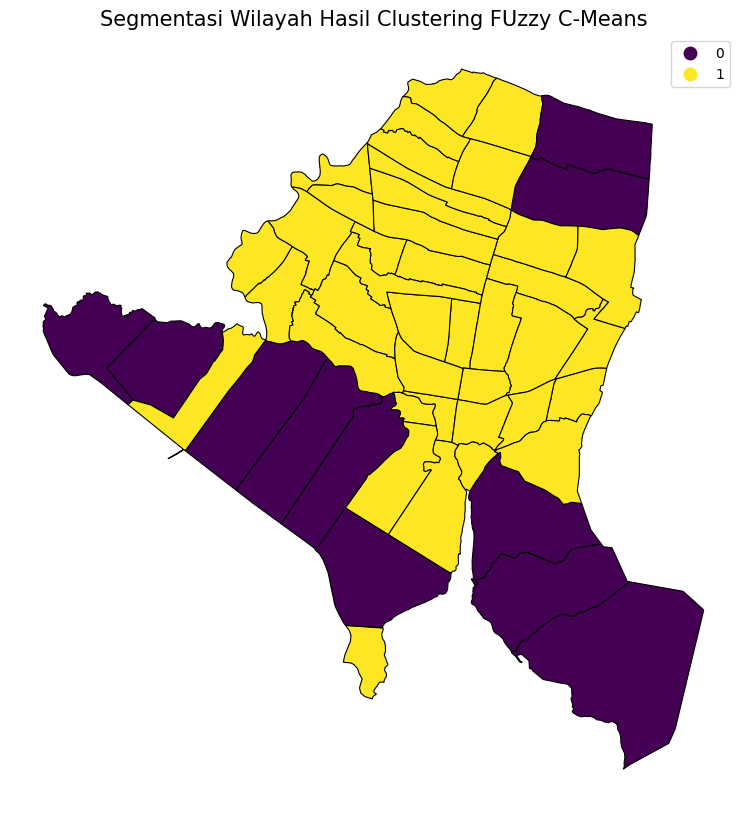

In [ ]:
#Segmentasi Wilayah Hasil Klaster
fig, ax = plt.subplots(figsize=(12, 10))
shapefile.plot(column='cluster', categorical=True, legend=True,
         cmap='viridis', linewidth=0.8, ax=ax, edgecolor='black')
plt.title('Segmentasi Wilayah Hasil Clustering FUzzy C-Means', fontsize=15)
plt.axis('off')
plt.show()

# **Evaluasi Kebijakan Pemerataan Jaringan Internet**

# quartil

In [ ]:
# 9. Hitung Rasio Pemerataan
data['rasio_per_1000'] = data['JUMLAH JARINGAN INTERNET'] / (data['JUMLAH PENDUDUK'] / 1000)
data['rasio_per_km2'] = data['JUMLAH JARINGAN INTERNET'] / data['LUAS WILAYAH']
data['rasio_per_kepadatan'] = data['JUMLAH JARINGAN INTERNET'] / data['KEPADATAN']

# 10. Hitung Skor Gabungan (tanpa z-score)
data['skor_total'] = (data['rasio_per_1000'] + data['rasio_per_km2'] + data['rasio_per_kepadatan']) / 3

# 11. Hitung Q1 dan Q3 dari skor_total
q1 = data['skor_total'].quantile(0.25)
q3 = data['skor_total'].quantile(0.75)

# 12. Klasifikasi Pemerataan berdasarkan Kuartil
def klasifikasi_q(skor):
    if skor < q1:
        return "Under-served"
    elif skor > q3:
        return "Over-served"
    else:
        return "Ideal"

data['kategori_pemerataan'] = data['skor_total'].apply(klasifikasi_q)

In [ ]:
q1

np.float64(0.38176229245074234)

In [ ]:
q3

np.float64(1.317581612058717)

In [ ]:
data['skor_total']

,skor_total
0,0.244420
1,0.219160
2,1.302208
3,2.564255
4,1.452861
5,0.639204
6,0.442990
7,0.932562
8,0.309400
9,0.408255


In [ ]:
data['kategori_pemerataan']

,kategori_pemerataan
0,Under-served
1,Under-served
2,Ideal
3,Over-served
4,Over-served
5,Ideal
6,Ideal
7,Ideal
8,Under-served
9,Ideal


# z score

In [ ]:
# 10. Hitung Z-Score dan Skor Gabungan
data['z1'] = zscore(data['rasio_per_1000'])
data['z2'] = zscore(data['rasio_per_km2'])
data['z3'] = zscore(data['rasio_per_kepadatan'])
data['skor_total'] = (data['z1'] + data['z2'] + data['z3']) / 3

# 11. Klasifikasi Pemerataan
def klasifikasi(z):
    if z < -0.5:
        return "Under-served"
    elif z > 0.5:
        return "Over-served"
    else:
        return "Ideal"

data['kategori_pemerataan'] = data['skor_total'].apply(klasifikasi)

In [ ]:
data['z1']

,z1
0,-0.692142
1,-0.559512
2,0.126872
3,-0.073027
4,-0.151782
5,-0.015867
6,-0.623488
7,-0.516151
8,-0.855926
9,-0.819133


In [ ]:
data['z2']

,z2
0,-0.745116
1,-0.789601
2,0.142241
3,1.380277
4,0.328899
5,-0.470586
6,-0.565503
7,-0.113484
8,-0.657921
9,-0.568927


In [ ]:
data['z3']

,z3
0,-0.240931
1,0.596876
2,-0.112497
3,-1.021010
4,-0.788736
5,1.332069
6,-0.769681
7,-0.486293
8,-0.855133
9,-0.950935


In [ ]:
data['skor_total']

,skor_total
0,-0.559397
1,-0.250746
2,0.052205
3,0.095413
4,-0.203873
5,0.281872
6,-0.652891
7,-0.371976
8,-0.789660
9,-0.779665


In [ ]:
data['kategori_pemerataan']

,kategori_pemerataan
0,Under-served
1,Ideal
2,Ideal
3,Ideal
4,Ideal
5,Ideal
6,Under-served
7,Ideal
8,Under-served
9,Under-served
